LAB 07: ROOT-FINDING METHODS

In [1]:
from math import exp, sqrt, log
import numpy as np
import matplotlib.pyplot as plt

Part I. 

This is our function $f(x) = e^{x-\sqrt{x}} -x $

In [2]:
def f(x):
    return exp(x-sqrt(x)) - x 

We compute for its derivative as well.

In [3]:
def df(x):
    return (1-(1/(2*sqrt(x))))*exp(x-sqrt(x)) - 1

We first define the Bisection and Newton's Methods.

In [4]:
def newton(f,x0,kmax=10):
    
    for k in range(1,kmax):
        xnew = x0 - (f(x0)/df(x0)) 
        x0 = xnew
        print(k,xnew)

    return xnew

In [5]:
def bisection(f,x0,x1,kmax=200,tol=1.e-10):
    f0=f(x0)
    for k in range(1,kmax):
        x2 = (x0+x1)/2.0
        f2 = f(x2)

        if f0*f2 < 0:
            x1 = x2
        else:
            x0, f0 = x2, f2

        x2new = (x0+x1)/2.0
        xdiff = abs(x2new - x2)

        print(k,x0,x1,x2new,xdiff,abs(f(x2new)))

        if abs(xdiff/x2new) < tol:
            break
    else:
        x2new = None

    return x2new

In [28]:
print("Newton Method:")
newton_sol = print("Newton Solution:", newton(f,0.5,kmax=10))
print(" ")
print("Bisection Method:")
bisection_sol = print("Bisection Solution:", bisection(f,0.5,2,kmax=200,tol=1.e-10))

Newton Method:
1 0.9107282751264427
2 0.996381032692429
3 0.9999934790412119
4 0.9999999999787387
5 1.0
6 1.0
7 1.0
8 1.0
9 1.0
Newton Solution: 1.0
 
Bisection Method:
1 0.5 1.25 0.875 0.375 0.06637439739511797
2 0.875 1.25 1.0625 0.1875 0.030267849707225514
3 0.875 1.0625 0.96875 0.09375 0.015868537639006752
4 0.96875 1.0625 1.015625 0.046875 0.007751383368331144
5 0.96875 1.015625 0.9921875 0.0234375 0.003921498981560134
6 0.9921875 1.015625 1.00390625 0.01171875 0.0019493090531037538
7 0.9921875 1.00390625 0.998046875 0.005859375 0.0009775160195890642
8 0.998046875 1.00390625 1.0009765625 0.0029296875 0.0004880428119875546
9 0.998046875 1.0009765625 0.99951171875 0.00146484375 0.00024420022722138057
10 0.99951171875 1.0009765625 1.000244140625 0.000732421875 0.00012205541103549322
11 0.99951171875 1.000244140625 0.9998779296875 0.0003662109375 6.103888150243986e-05
12 0.9998779296875 1.000244140625 1.00006103515625 0.00018310546875 3.0516646797762448e-05
13 0.9998779296875 1.000061

We see that the Newton method is faster than the bisection method. However, the strength of the bisection method is that it is always sure to converge, albeit slow.

We know define a new function that combines both the newton and bisection method. Our $f(x_0)$ and $f(x_1)$ must have opposite signs for this to work. Otherwise, this method will not work.

In [29]:
def combine(f, df, x0, x1, kmax = 200, tol = 1.e-50):
    f0 = f(x0)
    for k in range(1,kmax):
        x = x0 - (f(x0)/df(x0)) #this is the newton's method initially
        if x0 < x < x1:
            x0 = x
            f0 = f(x)
            df0 = df(x)
        else:
            x = (x0 + x1)/2 #then this is the bissection method
            if f0*f(x) < 0:
                x1 = x
            else:
                x0, f0 = x, f(x) 
        if abs(x1-x0) < tol or abs(f0) < tol:
                break              
        print(f"k = {k}: x0 = {x0:.8f}, x1 = {x1:.8f}, Root = {x:.8f}")           
    return x

In [30]:
root = combine(f, df, 0.5, 2)
x1 = 0.5
x2 = 2
print(r"f(x_1):", f(x1))
print(r"f(x_2):", f(x2))

k = 1: x0 = 0.91072828, x1 = 2.00000000, Root = 0.91072828
k = 2: x0 = 0.99638103, x1 = 2.00000000, Root = 0.99638103
k = 3: x0 = 0.99999348, x1 = 2.00000000, Root = 0.99999348
k = 4: x0 = 1.00000000, x1 = 2.00000000, Root = 1.00000000
f(x_1): 0.31293283941960903
f(x_2): -0.2035968106767665


Indeed, $f(x_0)$ and $f(x_1)$ have different signs using these $x_{0}$ = 0.5 and $x_{1}$ = 2.

PART B.

We first define a function $\psi$. 

In [31]:
def psi(x, wt, e):
    return x-e*np.sin(x) - wt

We also define its derivative.

In [32]:
def dpsi(x):
    return 1-e*np.cos(x) 

We simply create a new function that simply prints the root x using the combined method.

In [33]:
def combine_new(f, df, wt, e, x0 = 0, x1 = 2*np.pi, kmax = 200, tol = 1.e-10):
    f0=f(x0,wt,e)
    df0 = df(x0)
    for k in range(1,kmax):
        x = x0 - (f0/df(x0)) #this is the newton's method initially
        if x0 < x < x0:
            x0 = x
            f0 = f(x,wt,e)
            df0 = df(x)
        else:
            x = (x0 + x1)/2 #then this is the bissection method
            if f0*f(x,wt,e) < 0:
                x1 = x
            else:
                x0, f0 = x, f(x,wt,e) 
        if abs(x1-x0) < tol or abs(f0) < tol:
                break
    return x

We also create a code that linearly spaces $\omega*t$ 

In [34]:
e = 0.0167
wt_values = np.linspace(0,2*np.pi, 200)
psi_values = np.array([combine_new(psi, dpsi, wt, e, -0.5, 2*np.pi + 0.5) for wt in wt_values])
print(psi_values)

[-2.26432869e-11  3.21099393e-02  6.42193165e-02  9.63275702e-02
  1.28434140e-01  1.60538469e-01  1.92640000e-01  2.24738183e-01
  2.56832468e-01  2.88922313e-01  3.21007180e-01  3.53086537e-01
  3.85159858e-01  4.17226625e-01  4.49286328e-01  4.81338464e-01
  5.13382541e-01  5.45418075e-01  5.77444593e-01  6.09461631e-01
  6.41468737e-01  6.73465472e-01  7.05451406e-01  7.37426125e-01
  7.69389226e-01  8.01340318e-01  8.33279027e-01  8.65204990e-01
  8.97117860e-01  9.29017305e-01  9.60903008e-01  9.92774665e-01
  1.02463199e+00  1.05647472e+00  1.08830259e+00  1.12011536e+00
  1.15191282e+00  1.18369475e+00  1.21546098e+00  1.24721132e+00
  1.27894563e+00  1.31066376e+00  1.34236559e+00  1.37405103e+00
  1.40571998e+00  1.43737237e+00  1.46900816e+00  1.50062729e+00
  1.53222977e+00  1.56381557e+00  1.59538473e+00  1.62693726e+00
  1.65847322e+00  1.68999267e+00  1.72149569e+00  1.75298237e+00
  1.78445283e+00  1.81590719e+00  1.84734560e+00  1.87876821e+00
  1.91017519e+00  1.94156

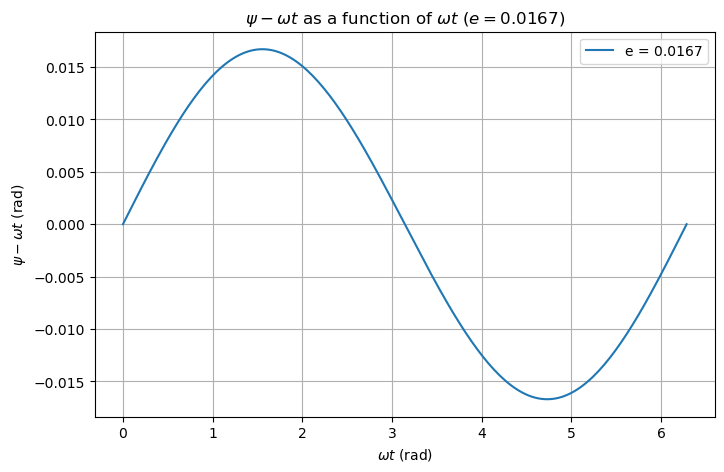

In [35]:
plt.figure(figsize=(8, 5))
plt.plot(wt_values, psi_values - wt_values, label=f'e = 0.0167')
plt.xlabel(r'$\omega t$ (rad)')
plt.ylabel(r'$\psi - \omega t$ (rad)')
plt.title(r'$\psi - \omega t$ as a function of $\omega t$ ($e = 0.0167$)')
plt.grid(True)
plt.legend()
plt.show()

In [36]:
e_values = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
e = 0.0167
wt_values = np.linspace(0,2*np.pi, 200)
for e in e_values:
    psi_values1 = np.array([combine_new(psi, dpsi, wt, e, -0.5, 2*np.pi + 0.5) for wt in wt_values])
    print(" "); print("e:", e); print("psi values1", psi_values1)

 
e: 0.1
psi values1 [-2.26432869e-11  3.50811955e-02  7.01575967e-02  1.05224422e-01
  1.40276913e-01  1.75310352e-01  2.10320065e-01  2.45301444e-01
  2.80249950e-01  3.15161126e-01  3.50030611e-01  3.84854146e-01
  4.19627584e-01  4.54346898e-01  4.89008192e-01  5.23607706e-01
  5.58141821e-01  5.92607069e-01  6.27000133e-01  6.61317856e-01
  6.95557244e-01  7.29715464e-01  7.63789852e-01  7.97777915e-01
  8.31677324e-01  8.65485924e-01  8.99201728e-01  9.32822917e-01
  9.66347839e-01  9.99775010e-01  1.03310310e+00  1.06633096e+00
  1.09945758e+00  1.13248209e+00  1.16540381e+00  1.19822218e+00
  1.23093679e+00  1.26354735e+00  1.29605374e+00  1.32845592e+00
  1.36075403e+00  1.39294828e+00  1.42503903e+00  1.45702673e+00
  1.48891194e+00  1.52069532e+00  1.55237763e+00  1.58395973e+00
  1.61544254e+00  1.64682709e+00  1.67811447e+00  1.70930586e+00
  1.74040250e+00  1.77140570e+00  1.80231682e+00  1.83313730e+00
  1.86386863e+00  1.89451234e+00  1.92507001e+00  1.95554328e+00
  1.

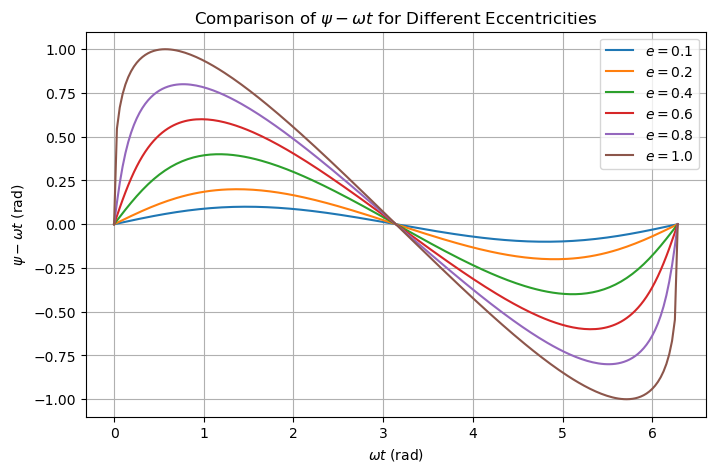

In [37]:
plt.figure(figsize = (8,5))
for e in e_values:
    psi_values1 = np.array([combine_new(psi, dpsi, wt, e, -0.5, 2*np.pi + 0.5) for wt in wt_values])
    plt.plot(wt_values, psi_values1 - wt_values, label=f'$e = {e}$')
plt.title(r'Comparison of $\psi - \omega t$ for Different Eccentricities')
plt.xlabel(r'$\omega t$ (rad)')
plt.ylabel(r'$\psi - \omega t$ (rad)')
plt.grid(True)
plt.legend()
plt.show()